
# C00c — Detector Transfer Under Self-History Humanization

## Scientific question

C00 showed that restricting effective generated self-history can move the completed-text
context-utility signature toward matched human writing. C00b replaced hard deletion with
a softer generation-side intervention: old generated tokens remain visible, but their
attention influence is attenuated as a function of age.

C00c asks whether that mechanistic intervention transfers to **independent AI-text
detectors**.

The primary confirmatory contrast is:

\[
\mathrm{L050}\;(\lambda=0.5)
\quad \text{vs.} \quad
\mathrm{L000}\;(\lambda=0),
\]

on the exact same 60 frozen RAID sources.

The main detector set is:

- **GLTR**, reproduced with the RAID implementation semantics: GPT-2 and the fraction
  of observed tokens whose zero-based rank is \(\le 10\);
- **Binoculars**, using the original Falcon-7B / Falcon-7B-Instruct pair when hardware
  permits;
- **GPTZero**, through its official API;
- **Originality.ai**, through its official API.

The detector score is oriented so that **larger always means more machine-like**.

For detector \(d\), define the matched machine-human baseline gap

\[
g_d
=
E_s[D_d(X_{s,\mathrm{L000}})-D_d(X_{s,H})].
\]

For intervention condition \(\lambda\),

\[
C_d(\lambda)
=
1-
\frac{
E_s[D_d(X_{s,\lambda})-D_d(X_{s,H})]
}{
E_s[D_d(X_{s,\mathrm{L000}})-D_d(X_{s,H})]
}.
\]

Thus \(C_d>0\) means the intervention moves that detector's score toward the matched
human distribution.

This is **not detector-targeted optimization**. The C00b texts were generated before
these detector scores are examined. The question is whether an independently motivated
mechanistic intervention transfers into detector space.

## Analysis populations

Detector scoring itself uses all 60 source pairs whenever a detector returns valid
scores. We do **not** condition the primary detector analysis on RELIC scorer eligibility,
because that would import the treatment-dependent length selection problem from C00b.

The RELIC \(U/L\) values are joined only in a later exploratory analysis.


In [1]:

from pathlib import Path
import gc
import json
import math
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from tqdm.auto import tqdm

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
RESULTS = ROOT / "results"

C00_DIR = RESULTS / "causal" / "C00_effective_history_gap_closure"
C00B_DIR = RESULTS / "causal" / "C00b_soft_self_history_attenuation"
OUT = RESULTS / "causal" / "C00c_detector_transfer_under_history_humanization"
OUT.mkdir(parents=True, exist_ok=True)

GEN_PATH = C00B_DIR / "generations.parquet"
ANALYSIS_PATH = C00B_DIR / "analysis_long.parquet"
PROMPT_PATH = C00_DIR / "frozen_prompts.parquet"

required = [GEN_PATH, ANALYSIS_PATH, PROMPT_PATH]
missing = [str(p) for p in required if not p.exists()]
assert not missing, f"Missing prerequisites:\n" + "\n".join(missing)

generations = pd.read_parquet(GEN_PATH).copy()
analysis = pd.read_parquet(ANALYSIS_PATH).copy()
prompts = pd.read_parquet(PROMPT_PATH).copy()

for df in [generations, analysis, prompts]:
    df["source_id"] = df["source_id"].astype(str)

CONDITIONS = ["L000", "L0125", "L025", "L050", "L100"]
PRIMARY_TREATMENT = "L050"

assert set(CONDITIONS).issubset(set(generations["condition"]))
assert generations["source_id"].nunique() == 60
assert not generations.duplicated(["source_id", "condition"]).any()

SOURCE_IDS = sorted(generations["source_id"].unique())
N_SOURCES = len(SOURCE_IDS)

N_BOOT = 10_000
BOOT_SEED = 20260902

print("ROOT:", ROOT)
print("OUT:", OUT)
print("sources:", N_SOURCES)
print("conditions:", CONDITIONS)
print("primary detector contrast:", PRIMARY_TREATMENT, "vs L000")


ROOT: ..
OUT: ../results/causal/C00c_detector_transfer_under_history_humanization
sources: 60
conditions: ['L000', 'L0125', 'L025', 'L050', 'L100']
primary detector contrast: L050 vs L000


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



## 1. Recover the exact matched RAID human texts

The C00 frozen human artifact stores the matched human \(U\) values but not the raw human
documents. We therefore recover the raw human row for each frozen `source_id` from the
same cached RAID training CSV already used by notebooks 16–17.

The recovered rows are cached locally so the 11.8 GB CSV is streamed only once.


In [2]:

RAID_CSV = Path.home() / ".cache" / "raid" / "train.csv"
HUMAN_TEXT_CACHE = OUT / "matched_human_texts.parquet"

if HUMAN_TEXT_CACHE.exists():
    human_text = pd.read_parquet(HUMAN_TEXT_CACHE)
    human_text["source_id"] = human_text["source_id"].astype(str)
    print("loaded cached human texts:", human_text.shape)

else:
    assert RAID_CSV.exists(), (
        f"Missing RAID train CSV: {RAID_CSV}\n"
        "Your earlier RAID notebooks used this cache. If it was removed, restore it with "
        "raid.utils.load_data(split='train') once."
    )

    wanted = set(SOURCE_IDS)
    pieces = []

    usecols = [
        "id",
        "source_id",
        "model",
        "attack",
        "domain",
        "title",
        "generation",
    ]

    for j, chunk in enumerate(pd.read_csv(
        RAID_CSV,
        usecols=usecols,
        chunksize=100_000,
    )):
        ids = chunk["id"].astype(str)

        keep = chunk[
            ids.isin(wanted)
            & chunk["model"].astype(str).eq("human")
            & chunk["attack"].astype(str).eq("none")
        ].copy()

        if len(keep):
            pieces.append(keep)

        found_ids = set()
        if pieces:
            found_ids = set(pd.concat(pieces, ignore_index=True)["id"].astype(str))

        if j % 20 == 0:
            print(f"chunks {j:4d} | matched humans found {len(found_ids)}/{N_SOURCES}")

        if wanted.issubset(found_ids):
            break

    raw_h = pd.concat(pieces, ignore_index=True).drop_duplicates("id")
    raw_h["source_id"] = raw_h["id"].astype(str)

    human_text = (
        raw_h[
            ["source_id", "domain", "title", "generation"]
        ]
        .rename(columns={"generation": "text"})
        .copy()
    )

    human_text.to_parquet(HUMAN_TEXT_CACHE, index=False)
    print("saved:", HUMAN_TEXT_CACHE)

assert human_text["source_id"].nunique() == N_SOURCES, (
    f"Recovered {human_text['source_id'].nunique()}/{N_SOURCES} matched humans."
)

display(
    human_text.groupby("domain")
    .size()
    .rename("n")
    .to_frame()
)


chunks    0 | matched humans found 0/60
chunks   20 | matched humans found 30/60
chunks   40 | matched humans found 30/60
saved: ../results/causal/C00c_detector_transfer_under_history_humanization/matched_human_texts.parquet


,n
domain,
news,30
wiki,30



## 2. Freeze the detector-evaluation corpus

Open-source GLTR is cheap enough to score the full attenuation grid.

Commercial APIs and exact Binoculars are more expensive, so the default **primary**
corpus contains only:

\[
H,\quad \mathrm{L000},\quad \mathrm{L050}.
\]

This is enough to answer the primary transfer question while avoiding unnecessary API
cost. Set `EXPENSIVE_FULL_GRID=True` only after the primary result is worth expanding.


In [3]:

EXPENSIVE_FULL_GRID = False

machine_corpus = generations[
    ["source_id", "condition", "generated_text"]
].rename(columns={"generated_text": "text"}).copy()

human_corpus = human_text[
    ["source_id", "text"]
].copy()
human_corpus["condition"] = "human"

detector_corpus = pd.concat(
    [human_corpus, machine_corpus],
    ignore_index=True,
)

detector_corpus["source_id"] = detector_corpus["source_id"].astype(str)
detector_corpus["text"] = detector_corpus["text"].astype(str)

assert not detector_corpus.duplicated(["source_id", "condition"]).any()
assert len(detector_corpus) == N_SOURCES * (1 + len(CONDITIONS))

PRIMARY_CONDITIONS = ["human", "L000", PRIMARY_TREATMENT]
EXPENSIVE_CONDITIONS = (
    ["human"] + CONDITIONS
    if EXPENSIVE_FULL_GRID
    else PRIMARY_CONDITIONS
)

primary_corpus = detector_corpus[
    detector_corpus["condition"].isin(PRIMARY_CONDITIONS)
].copy()

expensive_corpus = detector_corpus[
    detector_corpus["condition"].isin(EXPENSIVE_CONDITIONS)
].copy()

print("full corpus rows:", len(detector_corpus))
print("primary rows:", len(primary_corpus))
print("expensive-detector rows:", len(expensive_corpus))
display(
    detector_corpus.groupby("condition")
    .size()
    .rename("n")
    .to_frame()
)


full corpus rows: 360
primary rows: 180
expensive-detector rows: 180


,n
condition,
L000,60
L0125,60
L025,60
L050,60
L100,60
human,60



## 3. Exact RAID-style GLTR score

RAID's GLTR detector uses GPT-2 and reports the fraction of observed tokens whose
**zero-based next-token rank is at most 10**. Higher values are treated as more
machine-like.

The original RAID implementation sorts the full vocabulary. The implementation below is
mathematically equivalent but computes the target token's rank as the number of logits
strictly greater than the target logit, which is much cheaper.

GLTR is scored on all five C00b attenuation conditions plus matched humans.


In [4]:

from transformers import GPT2Tokenizer, GPT2LMHeadModel

GLTR_CACHE = OUT / "gltr_scores.parquet"
GLTR_MODEL = "gpt2"
GLTR_MAX_TOKENS = 1024
GLTR_RANK = 10

if GLTR_CACHE.exists():
    gltr_scores = pd.read_parquet(GLTR_CACHE)
    print("loaded GLTR cache:", gltr_scores.shape)

else:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    gltr_tok = GPT2Tokenizer.from_pretrained(GLTR_MODEL)
    gltr_model = GPT2LMHeadModel.from_pretrained(GLTR_MODEL)
    gltr_model.eval().to(device)

    bos_id = gltr_tok.bos_token_id
    assert bos_id is not None

    @torch.inference_mode()
    def raid_gltr_score(text):
        ids = gltr_tok(
            str(text),
            add_special_tokens=False,
            truncation=True,
            max_length=GLTR_MAX_TOKENS - 1,
            return_tensors="pt",
        )["input_ids"][0]

        ids = torch.cat([
            torch.tensor([bos_id], dtype=torch.long),
            ids.cpu(),
        ]).to(device)

        if ids.numel() <= 1:
            return np.nan

        logits = gltr_model(ids[None, :]).logits[0, :-1, :]
        targets = ids[1:]

        target_logits = logits.gather(
            1,
            targets[:, None],
        ).squeeze(1)

        # Zero-based rank, exactly matching np.where(sorted_logits == target)[0][0]
        # except for pathological exact ties.
        ranks = (logits > target_logits[:, None]).sum(dim=1)

        return float(
            (ranks <= GLTR_RANK)
            .float()
            .mean()
            .item()
        )

    rows = []

    for i, r in tqdm(
        detector_corpus.iterrows(),
        total=len(detector_corpus),
        desc="RAID-style GLTR",
    ):
        rows.append({
            "source_id": str(r["source_id"]),
            "condition": r["condition"],
            "detector": "GLTR",
            "machine_score": raid_gltr_score(r["text"]),
        })

    gltr_scores = pd.DataFrame(rows)
    gltr_scores.to_parquet(GLTR_CACHE, index=False)

    del gltr_model, gltr_tok
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print("saved:", GLTR_CACHE)

display(
    gltr_scores.groupby("condition")["machine_score"]
    .agg(["count", "mean", "std"])
)


RAID-style GLTR: 100%|████████████████████████████████████████████████████████████████████████████████| 360/360 [00:11<00:00, 31.45it/s]


saved: ../results/causal/C00c_detector_transfer_under_history_humanization/gltr_scores.parquet


,count,mean,std
condition,,,
L000,60,0.899857,0.031525
L0125,60,0.899250,0.029753
L025,60,0.897085,0.029455
L050,60,0.898144,0.029538
L100,60,0.898236,0.026815
human,60,0.719786,0.041501



## 4. Exact Binoculars — optional hardware-heavy block

The original Binoculars detector uses:

- observer: `tiiuae/falcon-7b`
- performer: `tiiuae/falcon-7b-instruct`
- global threshold \(0.9015310749\) on the original Binoculars score.

RAID orients its detector score as

\[
D_{\rm Binoculars}=1-\mathrm{BinocularsScore},
\]

so larger values are more machine-like.

**Important:** exact Binoculars keeps two 7B models resident. On an 8 GB GPU this is not
a sensible default run. This block is therefore off by default rather than silently
substituting a smaller model or quantized approximation.

Run it unchanged on a machine with enough accelerator/CPU memory if you want the exact
published detector. The output cache can then be copied back into this result directory.


In [5]:

RUN_BINOCULARS = False
BINOCULARS_CACHE = OUT / "binoculars_scores.parquet"

if BINOCULARS_CACHE.exists():
    binoculars_scores = pd.read_parquet(BINOCULARS_CACHE)
    print("loaded Binoculars cache:", binoculars_scores.shape)

elif RUN_BINOCULARS:
    # Install official package only when explicitly requested.
    # This stays inside the notebook, not a terminal workflow.
    try:
        from binoculars import Binoculars
    except ImportError:
        import subprocess, sys
        subprocess.check_call([
            sys.executable, "-m", "pip", "install",
            "git+https://github.com/ahans30/Binoculars.git",
        ])
        from binoculars import Binoculars

    bino = Binoculars()

    rows = []
    for _, r in tqdm(
        expensive_corpus.iterrows(),
        total=len(expensive_corpus),
        desc="Binoculars",
    ):
        raw_score = float(bino.compute_score(r["text"]))

        rows.append({
            "source_id": str(r["source_id"]),
            "condition": r["condition"],
            "detector": "Binoculars",
            "binoculars_raw_score": raw_score,
            # RAID orientation: larger = more machine-like
            "machine_score": 1.0 - raw_score,
            "vendor_label": (
                "AI-Generated"
                if raw_score < 0.9015310749276843
                else "Human-Generated"
            ),
        })

    binoculars_scores = pd.DataFrame(rows)
    binoculars_scores.to_parquet(BINOCULARS_CACHE, index=False)
    print("saved:", BINOCULARS_CACHE)

    del bino
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

else:
    binoculars_scores = pd.DataFrame()
    print(
        "SKIP Binoculars: RUN_BINOCULARS=False. "
        "Exact Falcon-7B/Falcon-7B-Instruct scoring is intentionally not replaced "
        "with a smaller proxy."
    )


SKIP Binoculars: RUN_BINOCULARS=False. Exact Falcon-7B/Falcon-7B-Instruct scoring is intentionally not replaced with a smaller proxy.



## 5. GPTZero official API

Set `GPTZERO_API_KEY` in the environment before running this cell.

The default endpoint matches RAID's detector wrapper:

`https://api.gptzero.me/v2/predict/text`

The parser supports both RAID's historical `completely_generated_prob` field and newer
responses exposing `class_probabilities.ai`.

Every successful response is cached so the notebook can resume without paying for the
same document twice.

By default only `human`, `L000`, and `L050` are submitted.


In [6]:

import requests

GPTZERO_CACHE = OUT / "gptzero_scores.parquet"
GPTZERO_API_KEY = os.getenv("GPTZERO_API_KEY", "").strip()
GPTZERO_URL = os.getenv(
    "GPTZERO_URL",
    "https://api.gptzero.me/v2/predict/text",
)

def extract_gptzero_score(payload):
    docs = payload.get("documents", [])
    if not docs:
        raise KeyError("GPTZero response has no documents[]")

    d = docs[0]

    # RAID-era schema.
    if "completely_generated_prob" in d:
        return float(d["completely_generated_prob"]), d.get("document_classification")

    # Newer schema.
    cp = d.get("class_probabilities", {})
    if "ai" in cp:
        return float(cp["ai"]), d.get("document_classification")

    # Some API versions nest prediction metadata.
    pred = d.get("prediction", {})
    cp = pred.get("class_probabilities", {})
    if "ai" in cp:
        return float(cp["ai"]), pred.get("document_classification")

    raise KeyError(
        "Could not find an AI probability in GPTZero response. "
        f"Top-level document keys: {sorted(d.keys())}"
    )

def post_with_retry(url, headers, payload, max_tries=6):
    last = None

    for attempt in range(max_tries):
        res = requests.post(
            url,
            headers=headers,
            json=payload,
            timeout=120,
        )
        last = res

        if res.status_code == 200:
            return res

        if res.status_code == 429 or 500 <= res.status_code < 600:
            wait = min(60, 2 ** attempt * 3)
            print(
                f"HTTP {res.status_code}; sleeping {wait}s "
                f"(attempt {attempt+1}/{max_tries})"
            )
            time.sleep(wait)
            continue

        raise RuntimeError(
            f"HTTP {res.status_code}: {res.text[:1000]}"
        )

    raise RuntimeError(
        f"API failed after {max_tries} tries: "
        f"{last.status_code if last is not None else 'no response'}"
    )

if GPTZERO_CACHE.exists():
    gptzero_scores = pd.read_parquet(GPTZERO_CACHE)
    print("loaded GPTZero cache:", gptzero_scores.shape)

elif not GPTZERO_API_KEY:
    gptzero_scores = pd.DataFrame()
    print(
        "SKIP GPTZero: GPTZERO_API_KEY is not set.\n"
        "Set it in the environment, then rerun this cell."
    )

else:
    headers = {"x-api-key": GPTZERO_API_KEY}
    rows = []

    for _, r in tqdm(
        expensive_corpus.iterrows(),
        total=len(expensive_corpus),
        desc="GPTZero",
    ):
        res = post_with_retry(
            GPTZERO_URL,
            headers,
            {"document": r["text"]},
        )

        payload = res.json()
        score, label = extract_gptzero_score(payload)

        rows.append({
            "source_id": str(r["source_id"]),
            "condition": r["condition"],
            "detector": "GPTZero",
            "machine_score": score,
            "vendor_label": label,
            "raw_response": json.dumps(payload),
        })

        # Resume-safe checkpoint.
        if len(rows) % 10 == 0:
            pd.DataFrame(rows).to_parquet(
                GPTZERO_CACHE,
                index=False,
            )

    gptzero_scores = pd.DataFrame(rows)
    gptzero_scores.to_parquet(GPTZERO_CACHE, index=False)
    print("saved:", GPTZERO_CACHE)

if len(gptzero_scores):
    display(
        gptzero_scores.groupby("condition")["machine_score"]
        .agg(["count", "mean", "std"])
    )


SKIP GPTZero: GPTZERO_API_KEY is not set.
Set it in the environment, then rerun this cell.



## 6. Originality.ai official API

Set `ORIGINALITY_API_KEY` in the environment before running this cell.

The default endpoint is the same endpoint used by RAID's Originality.ai wrapper:

`https://api.originality.ai/api/v1/scan/ai`

The endpoint can be overridden with `ORIGINALITY_URL` without editing the notebook if the
vendor changes API versions.

The request explicitly asks not to store the scan. The parser accepts the RAID-era
`score.ai` schema and a few obvious nested variants; if the current API schema differs,
the first error prints the returned keys instead of silently guessing.

By default only `human`, `L000`, and `L050` are submitted.


In [7]:

ORIGINALITY_CACHE = OUT / "originality_scores.parquet"
ORIGINALITY_API_KEY = os.getenv("ORIGINALITY_API_KEY", "").strip()
ORIGINALITY_URL = os.getenv(
    "ORIGINALITY_URL",
    "https://api.originality.ai/api/v1/scan/ai",
)

def extract_originality_score(payload):
    candidates = []

    score = payload.get("score")
    if isinstance(score, dict):
        candidates.append(score.get("ai"))

    if isinstance(payload.get("ai"), dict):
        candidates.append(payload["ai"].get("score"))
        candidates.append(payload["ai"].get("probability"))

    result = payload.get("result")
    if isinstance(result, dict):
        if isinstance(result.get("score"), dict):
            candidates.append(result["score"].get("ai"))
        candidates.append(result.get("ai_score"))

    candidates.append(payload.get("ai_score"))

    for x in candidates:
        if x is None:
            continue
        x = float(x)
        # Normalize percentages to [0,1] if needed.
        if 1 < x <= 100:
            x /= 100.0
        return x

    raise KeyError(
        "Could not find Originality AI score. "
        f"Top-level response keys: {sorted(payload.keys())}"
    )

if ORIGINALITY_CACHE.exists():
    originality_scores = pd.read_parquet(ORIGINALITY_CACHE)
    print("loaded Originality cache:", originality_scores.shape)

elif not ORIGINALITY_API_KEY:
    originality_scores = pd.DataFrame()
    print(
        "SKIP Originality.ai: ORIGINALITY_API_KEY is not set.\n"
        "Set it in the environment, then rerun this cell."
    )

else:
    headers = {
        "X-OAI-API-KEY": ORIGINALITY_API_KEY,
        "Accept": "application/json",
        "Content-Type": "application/json",
    }

    rows = []

    for _, r in tqdm(
        expensive_corpus.iterrows(),
        total=len(expensive_corpus),
        desc="Originality.ai",
    ):
        payload = {
            "content": r["text"],
            "storeScan": False,
        }

        res = post_with_retry(
            ORIGINALITY_URL,
            headers,
            payload,
        )

        response_payload = res.json()
        score = extract_originality_score(response_payload)

        rows.append({
            "source_id": str(r["source_id"]),
            "condition": r["condition"],
            "detector": "Originality",
            "machine_score": score,
            "raw_response": json.dumps(response_payload),
        })

        if len(rows) % 10 == 0:
            pd.DataFrame(rows).to_parquet(
                ORIGINALITY_CACHE,
                index=False,
            )

    originality_scores = pd.DataFrame(rows)
    originality_scores.to_parquet(
        ORIGINALITY_CACHE,
        index=False,
    )
    print("saved:", ORIGINALITY_CACHE)

if len(originality_scores):
    display(
        originality_scores.groupby("condition")["machine_score"]
        .agg(["count", "mean", "std"])
    )


SKIP Originality.ai: ORIGINALITY_API_KEY is not set.
Set it in the environment, then rerun this cell.



## 7. Merge all available detector scores

This cell works even if only GLTR has been run. Re-run it after adding GPTZero,
Originality.ai, or Binoculars caches.


In [8]:

score_frames = []

for name, df in [
    ("GLTR", gltr_scores),
    ("Binoculars", binoculars_scores),
    ("GPTZero", gptzero_scores),
    ("Originality", originality_scores),
]:
    if isinstance(df, pd.DataFrame) and len(df):
        x = df.copy()
        x["source_id"] = x["source_id"].astype(str)
        score_frames.append(
            x[
                [
                    c for c in [
                        "source_id",
                        "condition",
                        "detector",
                        "machine_score",
                        "vendor_label",
                    ]
                    if c in x.columns
                ]
            ]
        )

assert score_frames, "No detector score tables are available."

detector_scores = pd.concat(
    score_frames,
    ignore_index=True,
)

assert not detector_scores.duplicated(
    ["detector", "source_id", "condition"]
).any()

detector_scores.to_parquet(
    OUT / "detector_scores.parquet",
    index=False,
)

print("available detectors:", sorted(detector_scores["detector"].unique()))

display(
    detector_scores.groupby(
        ["detector", "condition"]
    )["machine_score"]
    .agg(["count", "mean", "std"])
)


available detectors: ['GLTR']


count      mean       std
detector condition                           
GLTR     L000          60  0.899857  0.031525
         L0125         60  0.899250  0.029753
         L025          60  0.897085  0.029455
         L050          60  0.898144  0.029538
         L100          60  0.898236  0.026815
         human         60  0.719786  0.041501


## 8. Primary detector transfer estimands

For each detector and each scored intervention condition:

1. compute the matched baseline human gap,
2. compute the paired intervention shift relative to `L000`,
3. compute the fraction of the detector's machine-human gap closed.

Bootstrap resampling is over frozen source IDs, preserving the matched
human / baseline / treatment triplet.

The primary claim concerns `L050`. Other attenuation strengths are exploratory.


In [9]:

def detector_gap_stats(wide, treatment, n_boot=N_BOOT, seed=BOOT_SEED):
    pair = wide[
        ["human", "L000", treatment]
    ].dropna()

    h = pair["human"].to_numpy(float)
    b = pair["L000"].to_numpy(float)
    t = pair[treatment].to_numpy(float)

    baseline_gap = float(np.mean(b - h))
    treatment_gap = float(np.mean(t - h))
    shift = float(np.mean(t - b))

    closure = (
        1.0 - treatment_gap / baseline_gap
        if abs(baseline_gap) > 1e-12
        else np.nan
    )

    rr = np.random.default_rng(seed)
    bs_gap = np.empty(n_boot)
    bs_tgap = np.empty(n_boot)
    bs_shift = np.empty(n_boot)
    bs_closure = np.full(n_boot, np.nan)

    n = len(pair)

    for k in range(n_boot):
        ix = rr.integers(0, n, n)

        bg = np.mean(b[ix] - h[ix])
        tg = np.mean(t[ix] - h[ix])
        sh = np.mean(t[ix] - b[ix])

        bs_gap[k] = bg
        bs_tgap[k] = tg
        bs_shift[k] = sh

        if abs(bg) > 1e-12:
            bs_closure[k] = 1.0 - tg / bg

    valid_c = np.isfinite(bs_closure)

    return {
        "n": n,
        "human_mean": float(h.mean()),
        "L000_mean": float(b.mean()),
        "treatment_mean": float(t.mean()),

        "baseline_gap": baseline_gap,
        "baseline_gap_ci_low": float(np.quantile(bs_gap, 0.025)),
        "baseline_gap_ci_high": float(np.quantile(bs_gap, 0.975)),

        "treatment_gap": treatment_gap,
        "treatment_gap_ci_low": float(np.quantile(bs_tgap, 0.025)),
        "treatment_gap_ci_high": float(np.quantile(bs_tgap, 0.975)),

        "treatment_minus_L000": shift,
        "shift_ci_low": float(np.quantile(bs_shift, 0.025)),
        "shift_ci_high": float(np.quantile(bs_shift, 0.975)),

        "closure": closure,
        "closure_ci_low": (
            float(np.quantile(bs_closure[valid_c], 0.025))
            if valid_c.any() else np.nan
        ),
        "closure_ci_high": (
            float(np.quantile(bs_closure[valid_c], 0.975))
            if valid_c.any() else np.nan
        ),
        "valid_closure_boot": int(valid_c.sum()),
    }


rows = []

for det_i, detector in enumerate(
    sorted(detector_scores["detector"].unique())
):
    ds = detector_scores[
        detector_scores["detector"].eq(detector)
    ]

    wide = ds.pivot(
        index="source_id",
        columns="condition",
        values="machine_score",
    )

    treatments = [
        c for c in CONDITIONS
        if c != "L000"
        and c in wide.columns
    ]

    for cond_i, treatment in enumerate(treatments):
        if not {"human", "L000", treatment}.issubset(wide.columns):
            continue

        est = detector_gap_stats(
            wide,
            treatment,
            seed=BOOT_SEED + 40000 + 100 * det_i + cond_i,
        )

        rows.append({
            "detector": detector,
            "condition": treatment,
            "primary": treatment == PRIMARY_TREATMENT,
            **est,
        })

detector_transfer = pd.DataFrame(rows)

detector_transfer.to_csv(
    OUT / "detector_gap_closure.csv",
    index=False,
)

print("=== PRIMARY L050 DETECTOR TRANSFER ===")

primary_transfer = detector_transfer[
    detector_transfer["condition"].eq(PRIMARY_TREATMENT)
].copy()

display(
    primary_transfer[
        [
            "detector",
            "n",
            "human_mean",
            "L000_mean",
            "treatment_mean",
            "baseline_gap",
            "baseline_gap_ci_low",
            "baseline_gap_ci_high",
            "treatment_minus_L000",
            "shift_ci_low",
            "shift_ci_high",
            "closure",
            "closure_ci_low",
            "closure_ci_high",
        ]
    ]
)

print("\n=== ALL AVAILABLE ATTENUATION CONDITIONS ===")
display(detector_transfer)


=== PRIMARY L050 DETECTOR TRANSFER ===


,detector,n,human_mean,L000_mean,treatment_mean,baseline_gap,baseline_gap_ci_low,baseline_gap_ci_high,treatment_minus_L000,shift_ci_low,shift_ci_high,closure,closure_ci_low,closure_ci_high
2,GLTR,60,0.719786,0.899857,0.898144,0.180071,0.167289,0.19304,-0.001713,-0.006706,0.003226,0.009513,-0.018132,0.037345



=== ALL AVAILABLE ATTENUATION CONDITIONS ===


,detector,condition,primary,n,human_mean,L000_mean,treatment_mean,baseline_gap,baseline_gap_ci_low,baseline_gap_ci_high,treatment_gap,treatment_gap_ci_low,treatment_gap_ci_high,treatment_minus_L000,shift_ci_low,shift_ci_high,closure,closure_ci_low,closure_ci_high,valid_closure_boot
0,GLTR,L0125,False,60,0.719786,0.899857,0.899250,0.180071,0.167467,0.193146,0.179465,0.167048,0.192363,-0.000606,-0.004554,0.003096,0.003365,-0.017575,0.025061,10000
1,GLTR,L025,False,60,0.719786,0.899857,0.897085,0.180071,0.167404,0.192923,0.177299,0.165104,0.190039,-0.002772,-0.007513,0.001887,0.015391,-0.010568,0.041086,10000
2,GLTR,L050,True,60,0.719786,0.899857,0.898144,0.180071,0.167289,0.193040,0.178358,0.165380,0.191737,-0.001713,-0.006706,0.003226,0.009513,-0.018132,0.037345,10000
3,GLTR,L100,False,60,0.719786,0.899857,0.898236,0.180071,0.167477,0.192682,0.178450,0.166118,0.190824,-0.001621,-0.007572,0.004095,0.009000,-0.023441,0.041386,10000



## 9. Distribution-level detector movement

Gap closure is meaningful only if the detector actually separates `L000` from humans on
this population. This figure therefore shows the raw mean score trajectory for each
detector rather than hiding everything inside a ratio.

The horizontal human line makes overshoot visible.


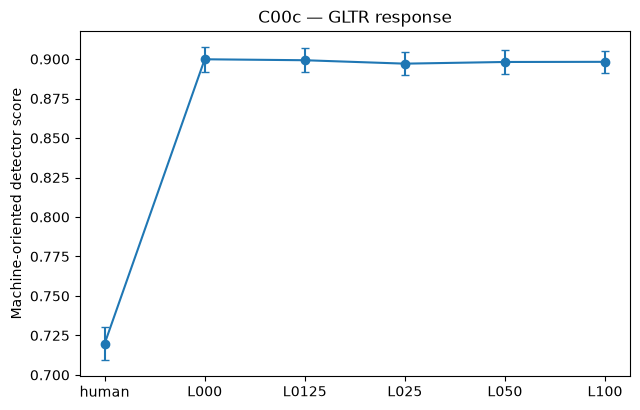

saved: ../results/causal/C00c_detector_transfer_under_history_humanization/gltr_condition_response.png


In [10]:

for detector in sorted(detector_scores["detector"].unique()):
    ds = detector_scores[
        detector_scores["detector"].eq(detector)
    ].copy()

    order = ["human", "L000", "L0125", "L025", "L050", "L100"]
    order = [c for c in order if c in set(ds["condition"])]

    summary = (
        ds.groupby("condition")["machine_score"]
        .agg(["mean", "sem"])
        .reindex(order)
    )

    fig, ax = plt.subplots(figsize=(6.5, 4.2))

    x = np.arange(len(summary))

    ax.errorbar(
        x,
        summary["mean"],
        yerr=1.96 * summary["sem"],
        marker="o",
        capsize=3,
    )

    ax.set_xticks(x)
    ax.set_xticklabels(summary.index)
    ax.set_ylabel("Machine-oriented detector score")
    ax.set_title(f"C00c — {detector} response")

    fig.tight_layout()

    p = OUT / f"{detector.lower()}_condition_response.png"
    fig.savefig(p, dpi=200, bbox_inches="tight")
    plt.show()

    print("saved:", p)



## 10. RAID-like 5% FPR reference — descriptive only

For a quick attack-style view, use the matched human score distribution to set its
empirical 95th percentile as a machine threshold and report the fraction of machine
documents above it.

Because the same 60 humans both define and summarize this threshold, this is **not an
independent estimate of TPR@5%FPR** and should not be used as the headline result.

If C00c is promising, the proper confirmatory version should freeze this threshold on an
independent RAID human calibration pool and evaluate the 60 frozen sources afterward.


In [13]:
# ============================================================
# 10. Independent human calibration pool for 5% FPR
#
# 500 RAID humans:
#   - 250 news
#   - 250 wiki
#   - attack == none
#   - excludes the frozen 60 C00 source IDs
#
# Selection is deterministic by SHA-256, not row order.
# ============================================================

import hashlib
from transformers import GPT2Tokenizer, GPT2LMHeadModel

CAL_PER_DOMAIN = 250
CAL_DOMAINS = ["news", "wiki"]
CAL_TOTAL = CAL_PER_DOMAIN * len(CAL_DOMAINS)
CAL_SEED = 20260902

CAL_TEXT_CACHE = (
    OUT / "independent_human_calibration_texts.parquet"
)

GLTR_CAL_CACHE = (
    OUT / "gltr_independent_human_calibration.parquet"
)


def stable_hash64(source_id):
    s = f"{CAL_SEED}|{source_id}".encode("utf-8")

    return int(
        hashlib.sha256(s).hexdigest()[:16],
        16,
    )


# ------------------------------------------------------------
# Recover the independent human calibration texts
# ------------------------------------------------------------

if CAL_TEXT_CACHE.exists():

    calibration_humans = pd.read_parquet(
        CAL_TEXT_CACHE
    )

    calibration_humans["source_id"] = (
        calibration_humans["source_id"].astype(str)
    )

    print(
        "loaded calibration humans:",
        calibration_humans.shape,
    )

else:

    frozen_ids = set(
        str(x)
        for x in SOURCE_IDS
    )

    best = {
        d: pd.DataFrame()
        for d in CAL_DOMAINS
    }

    usecols = [
        "id",
        "model",
        "attack",
        "domain",
        "title",
        "generation",
    ]

    for j, chunk in enumerate(
        pd.read_csv(
            RAID_CSV,
            usecols=usecols,
            chunksize=100_000,
        )
    ):

        x = chunk[
            chunk["model"].astype(str).eq("human")
            & chunk["attack"].astype(str).eq("none")
            & chunk["domain"].astype(str).isin(
                CAL_DOMAINS
            )
        ].copy()

        if len(x):

            x["source_id"] = (
                x["id"].astype(str)
            )

            x = x[
                ~x["source_id"].isin(
                    frozen_ids
                )
            ].copy()

        if len(x):

            x["_hash"] = (
                x["source_id"]
                .map(stable_hash64)
                .astype("uint64")
            )

            for domain in CAL_DOMAINS:

                xd = x[
                    x["domain"]
                    .astype(str)
                    .eq(domain)
                ]

                if not len(xd):
                    continue

                best[domain] = (
                    pd.concat(
                        [
                            best[domain],
                            xd,
                        ],
                        ignore_index=True,
                    )
                    .drop_duplicates(
                        "source_id"
                    )
                    .nsmallest(
                        CAL_PER_DOMAIN,
                        "_hash",
                    )
                    .copy()
                )

        if j % 20 == 0:

            print(
                f"chunks {j:4d} | "
                + " | ".join(
                    f"{d}:"
                    f"{len(best[d])}/"
                    f"{CAL_PER_DOMAIN}"
                    for d in CAL_DOMAINS
                )
            )


    assert all(
        len(best[d]) == CAL_PER_DOMAIN
        for d in CAL_DOMAINS
    )

    calibration_humans = pd.concat(
        [
            best[d].nsmallest(
                CAL_PER_DOMAIN,
                "_hash",
            )
            for d in CAL_DOMAINS
        ],
        ignore_index=True,
    )

    calibration_humans = (
        calibration_humans[
            [
                "source_id",
                "domain",
                "title",
                "generation",
                "_hash",
            ]
        ]
        .rename(
            columns={
                "generation": "text"
            }
        )
        .sort_values(
            [
                "domain",
                "_hash",
            ]
        )
        .reset_index(drop=True)
    )

    calibration_humans.to_parquet(
        CAL_TEXT_CACHE,
        index=False,
    )

    print(
        "saved:",
        CAL_TEXT_CACHE,
    )


assert len(calibration_humans) == CAL_TOTAL

assert (
    calibration_humans["source_id"]
    .nunique()
    == CAL_TOTAL
)

assert not (
    set(
        calibration_humans["source_id"]
    )
    & set(SOURCE_IDS)
)

display(
    calibration_humans
    .groupby("domain")
    .size()
    .rename("n")
    .to_frame()
)


# ------------------------------------------------------------
# Score calibration humans with the exact same GLTR statistic
# ------------------------------------------------------------

if GLTR_CAL_CACHE.exists():

    gltr_calibration = pd.read_parquet(
        GLTR_CAL_CACHE
    )

    print(
        "loaded GLTR calibration:",
        gltr_calibration.shape,
    )

else:

    device = torch.device(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

    cal_tok = GPT2Tokenizer.from_pretrained(
        "gpt2"
    )

    cal_model = GPT2LMHeadModel.from_pretrained(
        "gpt2"
    )

    cal_model.eval().to(device)

    bos_id = cal_tok.bos_token_id

    assert bos_id is not None


    @torch.inference_mode()
    def calibration_gltr_score(text):

        ids = cal_tok(
            str(text),
            add_special_tokens=False,
            truncation=True,
            max_length=1023,
            return_tensors="pt",
        )["input_ids"][0]

        ids = torch.cat(
            [
                torch.tensor(
                    [bos_id],
                    dtype=torch.long,
                ),
                ids.cpu(),
            ]
        ).to(device)

        if ids.numel() <= 1:
            return np.nan

        logits = (
            cal_model(
                ids[None, :]
            )
            .logits[0, :-1, :]
        )

        targets = ids[1:]

        target_logits = logits.gather(
            1,
            targets[:, None],
        ).squeeze(1)

        # RAID GLTR zero-based token rank.
        ranks = (
            logits
            > target_logits[:, None]
        ).sum(dim=1)

        return float(
            (ranks <= 10)
            .float()
            .mean()
            .item()
        )


    rows = []

    for _, r in tqdm(
        calibration_humans.iterrows(),
        total=len(calibration_humans),
        desc="GLTR calibration humans",
    ):

        rows.append({
            "source_id":
                str(r["source_id"]),

            "domain":
                r["domain"],

            "machine_score":
                calibration_gltr_score(
                    r["text"]
                ),
        })


    gltr_calibration = pd.DataFrame(
        rows
    )

    gltr_calibration.to_parquet(
        GLTR_CAL_CACHE,
        index=False,
    )

    del cal_model, cal_tok

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print(
        "saved:",
        GLTR_CAL_CACHE,
    )


print(
    "GLTR calibration humans:",
    len(gltr_calibration),
)

display(
    gltr_calibration[
        "machine_score"
    ]
    .describe()
    .to_frame()
    .T
)

chunks    0 | news:0/250 | wiki:0/250
chunks   20 | news:250/250 | wiki:0/250
chunks   40 | news:250/250 | wiki:0/250
saved: ../results/causal/C00c_detector_transfer_under_history_humanization/independent_human_calibration_texts.parquet


,n
domain,
news,250
wiki,250


GLTR calibration humans: 100%|████████████████████████████████████████████████████████████████████████| 500/500 [00:15<00:00, 32.89it/s]


saved: ../results/causal/C00c_detector_transfer_under_history_humanization/gltr_independent_human_calibration.parquet
GLTR calibration humans: 500


,count,mean,std,min,25%,50%,75%,max
machine_score,500.0,0.722843,0.043109,0.574803,0.698977,0.723284,0.751448,0.84322


In [11]:

# rate_rows = []

# for detector in sorted(detector_scores["detector"].unique()):
#     ds = detector_scores[
#         detector_scores["detector"].eq(detector)
#     ].copy()

#     h = ds.loc[
#         ds["condition"].eq("human"),
#         "machine_score",
#     ].dropna().to_numpy(float)

#     if len(h) < 20:
#         continue

#     threshold = float(np.quantile(h, 0.95))

#     for condition, g in ds.groupby("condition"):
#         vals = g["machine_score"].dropna().to_numpy(float)

#         rate_rows.append({
#             "detector": detector,
#             "condition": condition,
#             "n": len(vals),
#             "matched_human_q95_threshold": threshold,
#             "fraction_above_threshold": float(
#                 np.mean(vals > threshold)
#             ),
#         })

# raid_like_rates = pd.DataFrame(rate_rows)

# display(
#     raid_like_rates[
#         raid_like_rates["condition"].isin(
#             ["human", "L000", PRIMARY_TREATMENT]
#         )
#     ]
# )

# raid_like_rates.to_csv(
#     OUT / "descriptive_q95_detection_rates.csv",
#     index=False,
# )


,detector,condition,n,matched_human_q95_threshold,fraction_above_threshold
0,GLTR,L000,60,0.783397,1.00
3,GLTR,L050,60,0.783397,1.00
5,GLTR,human,60,0.783397,0.05



## 11. Exploratory bridge back to the mechanistic coordinates

This analysis is deliberately secondary.

For sources that are RELIC-eligible in both `L000` and `L050`, compare source-level
detector movement with:

\[
\Delta U_{\rm long}
\]

and

\[
\Delta L_8.
\]

A correlation here is **not required** for the population-level causal transfer claim.
It only asks whether sources with larger mechanistic shifts also tend to have larger
detector-score shifts.


GLTR threshold: 0.7937220335006714
target calibration FPR: 0.05
realized calibration FPR: 0.048

held-out human FPR: 0.016666666666666666


,n,TPR
condition,,
L000,60,1.0
L0125,60,1.0
L025,60,1.0
L050,60,1.0
L100,60,1.0


=== GLTR TPR TRANSFER @ 5% FPR ===


,condition,n,baseline_TPR,treatment_TPR,delta_TPR,delta_TPR_ci_low,delta_TPR_ci_high,evasion_fraction_among_L000_detected,new_detection_fraction_among_L000_missed
0,L0125,60,1.0,1.0,0.0,0.0,0.0,0.0,NaN
1,L025,60,1.0,1.0,0.0,0.0,0.0,0.0,NaN
2,L050,60,1.0,1.0,0.0,0.0,0.0,0.0,NaN
3,L100,60,1.0,1.0,0.0,0.0,0.0,0.0,NaN


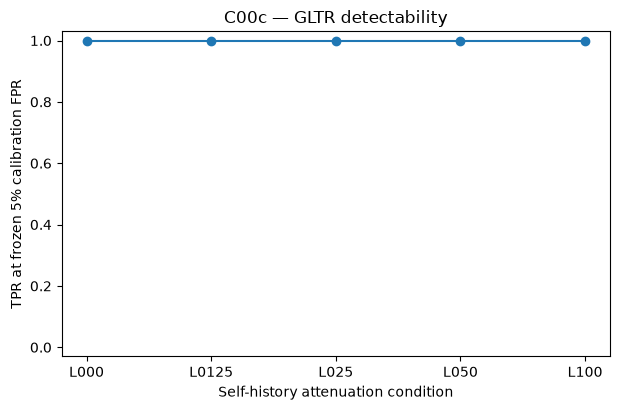

saved: ../results/causal/C00c_detector_transfer_under_history_humanization/gltr_tpr_at_5pct_fpr.png


In [14]:
# ============================================================
# 11. GLTR TPR at independently calibrated 5% FPR
# ============================================================

TARGET_FPR = 0.05


# ------------------------------------------------------------
# Freeze threshold ONLY on the independent 500 humans
#
# Higher GLTR score = more machine-like.
#
# Use score > threshold rather than >= because GLTR is
# discrete/tied; this makes calibration conservative.
# ------------------------------------------------------------

cal_scores = (
    gltr_calibration[
        "machine_score"
    ]
    .dropna()
    .to_numpy(float)
)

assert len(cal_scores) == CAL_TOTAL

GLTR_THRESHOLD = float(
    np.quantile(
        cal_scores,
        1 - TARGET_FPR,
        method="higher",
    )
)

calibration_fpr = float(
    np.mean(
        cal_scores
        > GLTR_THRESHOLD
    )
)

print(
    "GLTR threshold:",
    GLTR_THRESHOLD,
)

print(
    "target calibration FPR:",
    TARGET_FPR,
)

print(
    "realized calibration FPR:",
    calibration_fpr,
)


# ------------------------------------------------------------
# Evaluate the frozen 60-source C00 corpus
# ------------------------------------------------------------

gltr_eval = (
    detector_scores[
        detector_scores[
            "detector"
        ].eq("GLTR")
    ]
    .copy()
)

gltr_eval["detected_machine"] = (
    gltr_eval["machine_score"]
    > GLTR_THRESHOLD
)


# Held-out FPR:
# these 60 humans were NEVER used to choose threshold.
heldout_human = gltr_eval[
    gltr_eval[
        "condition"
    ].eq("human")
]

heldout_fpr = float(
    heldout_human[
        "detected_machine"
    ].mean()
)

print(
    "\nheld-out human FPR:",
    heldout_fpr,
)


# ------------------------------------------------------------
# TPR for every machine condition
# ------------------------------------------------------------

tpr_table = (
    gltr_eval[
        gltr_eval[
            "condition"
        ].ne("human")
    ]
    .groupby("condition")
    ["detected_machine"]
    .agg(
        n="size",
        TPR="mean",
    )
    .reindex(
        [
            "L000",
            "L0125",
            "L025",
            "L050",
            "L100",
        ]
    )
)

display(tpr_table)


# ------------------------------------------------------------
# Paired source-level ΔTPR vs L000
# ------------------------------------------------------------

wide = (
    gltr_eval[
        gltr_eval[
            "condition"
        ].ne("human")
    ]
    .pivot(
        index="source_id",
        columns="condition",
        values="detected_machine",
    )
)

rows = []

for cond_i, treatment in enumerate(
    [
        "L0125",
        "L025",
        "L050",
        "L100",
    ]
):

    pair = (
        wide[
            [
                "L000",
                treatment,
            ]
        ]
        .dropna()
        .astype(float)
    )

    b = pair[
        "L000"
    ].to_numpy()

    t = pair[
        treatment
    ].to_numpy()

    d = t - b

    baseline_tpr = float(
        b.mean()
    )

    treatment_tpr = float(
        t.mean()
    )

    delta_tpr = float(
        d.mean()
    )


    # Among texts detected at baseline,
    # what fraction evade after intervention?
    originally_detected = (
        b == 1
    )

    if originally_detected.any():

        evasion_fraction = float(
            np.mean(
                t[
                    originally_detected
                ]
                == 0
            )
        )

    else:

        evasion_fraction = np.nan


    # Conversely, how often does intervention create
    # a new positive among baseline misses?
    originally_missed = (
        b == 0
    )

    if originally_missed.any():

        new_detection_fraction = float(
            np.mean(
                t[
                    originally_missed
                ]
                == 1
            )
        )

    else:

        new_detection_fraction = np.nan


    rr = np.random.default_rng(
        BOOT_SEED
        + 51000
        + cond_i
    )

    bs = np.empty(
        N_BOOT
    )

    for k in range(
        N_BOOT
    ):

        ix = rr.integers(
            0,
            len(d),
            len(d),
        )

        bs[k] = d[
            ix
        ].mean()


    rows.append({
        "condition":
            treatment,

        "n":
            len(pair),

        "baseline_TPR":
            baseline_tpr,

        "treatment_TPR":
            treatment_tpr,

        "delta_TPR":
            delta_tpr,

        "delta_TPR_ci_low":
            np.quantile(
                bs,
                0.025,
            ),

        "delta_TPR_ci_high":
            np.quantile(
                bs,
                0.975,
            ),

        "evasion_fraction_among_L000_detected":
            evasion_fraction,

        "new_detection_fraction_among_L000_missed":
            new_detection_fraction,
    })


gltr_tpr_transfer = pd.DataFrame(
    rows
)

print(
    "=== GLTR TPR TRANSFER @ 5% FPR ==="
)

display(
    gltr_tpr_transfer
)


gltr_tpr_transfer.to_csv(
    OUT
    / "gltr_tpr_transfer_at_5pct_fpr.csv",
    index=False,
)


# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

plot = (
    tpr_table
    .reset_index()
    .dropna()
)

fig, ax = plt.subplots(
    figsize=(6.3, 4.2)
)

ax.plot(
    plot["condition"],
    plot["TPR"],
    marker="o",
)

ax.set_ylim(
    -0.03,
    1.03,
)

ax.set_ylabel(
    "TPR at frozen 5% calibration FPR"
)

ax.set_xlabel(
    "Self-history attenuation condition"
)

ax.set_title(
    "C00c — GLTR detectability"
)

fig.tight_layout()

p = (
    OUT
    / "gltr_tpr_at_5pct_fpr.png"
)

fig.savefig(
    p,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    "saved:",
    p,
)

In [12]:

# mech = analysis[
#     analysis["condition"].isin(["L000", PRIMARY_TREATMENT])
# ].copy()

# needed_mech = ["source_id", "condition", "U_long", "L_8"]
# assert set(needed_mech).issubset(mech.columns)

# mech_w = mech.pivot(
#     index="source_id",
#     columns="condition",
#     values=["U_long", "L_8"],
# )

# mech_delta = pd.DataFrame({
#     "source_id": mech_w.index.astype(str),
#     "delta_U_long": (
#         mech_w[("U_long", PRIMARY_TREATMENT)]
#         - mech_w[("U_long", "L000")]
#     ).to_numpy(),
#     "delta_L8": (
#         mech_w[("L_8", PRIMARY_TREATMENT)]
#         - mech_w[("L_8", "L000")]
#     ).to_numpy(),
# })

# corr_rows = []

# for detector in sorted(detector_scores["detector"].unique()):
#     ds = detector_scores[
#         detector_scores["detector"].eq(detector)
#         & detector_scores["condition"].isin(
#             ["L000", PRIMARY_TREATMENT]
#         )
#     ]

#     w = ds.pivot(
#         index="source_id",
#         columns="condition",
#         values="machine_score",
#     )

#     if not {"L000", PRIMARY_TREATMENT}.issubset(w.columns):
#         continue

#     d = pd.DataFrame({
#         "source_id": w.index.astype(str),
#         "delta_detector": (
#             w[PRIMARY_TREATMENT] - w["L000"]
#         ).to_numpy(),
#     }).merge(
#         mech_delta,
#         on="source_id",
#         how="inner",
#     ).dropna()

#     corr_rows.append({
#         "detector": detector,
#         "n": len(d),
#         "pearson_detector_vs_delta_U_long":
#             d["delta_detector"].corr(d["delta_U_long"]),
#         "pearson_detector_vs_delta_L8":
#             d["delta_detector"].corr(d["delta_L8"]),
#         "spearman_detector_vs_delta_U_long":
#             d["delta_detector"].corr(d["delta_U_long"], method="spearman"),
#         "spearman_detector_vs_delta_L8":
#             d["delta_detector"].corr(d["delta_L8"], method="spearman"),
#     })

# mechanism_correlations = pd.DataFrame(corr_rows)
# display(mechanism_correlations)

# mechanism_correlations.to_csv(
#     OUT / "detector_mechanism_correlations_exploratory.csv",
#     index=False,
# )


,detector,n,pearson_detector_vs_delta_U_long,pearson_detector_vs_delta_L8,spearman_detector_vs_delta_U_long,spearman_detector_vs_delta_L8
0,GLTR,19,0.359952,0.363333,0.450877,0.408772



## 12. Interpretation gate

The useful C00c outcomes are:

### A. Broad transfer

If several detectors satisfy

\[
E[D(X_{\rm L050})-D(X_{\rm L000})] < 0
\]

and the baseline detector gap is positive, then soft history attenuation changes a
machine-writing trace that multiple detectors exploit.

### B. Detector-specific transfer

If likelihood/rank detectors move but opaque commercial detectors do not, that suggests
the history intervention acts on only one detector-relevant axis.

### C. No transfer

If \(U\) moves strongly while independent detector scores remain unchanged, then \(U\)
is a mechanistic process trace but not an important coordinate for those detectors.

### D. Opposite transfer

If some detectors become *more* confident that the attenuated text is machine-generated,
that is also informative: detector space is not one-dimensional, and humanizing one
trace can expose or amplify another.

No detector score in this notebook is used to tune \(\lambda\). If a later intervention
is selected using detector outcomes, that later experiment must be clearly separated
from this confirmatory transfer test.
